In [11]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

X_train = pd.read_csv(
    PROJECT_ROOT / "data/processed/ml/X_train.csv"
)
X_test = pd.read_csv(
    PROJECT_ROOT / "data/processed/ml/X_test.csv"
)
y_train = pd.read_csv(
    PROJECT_ROOT / "data/processed/ml/y_train.csv"
)["is_late"]
y_test = pd.read_csv(
    PROJECT_ROOT / "data/processed/ml/y_test.csv"
)["is_late"]

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nFeature data types:")
print(X_train.dtypes)

Training features: (33562, 11)
Test features: (8391, 11)

Training target distribution:
is_late
0    0.701
1    0.299
Name: proportion, dtype: float64

Feature data types:
weather                            str
traffic_density                    str
vehicle_condition                int64
order_type                         str
vehicle_type                       str
festival                           str
city                               str
restaurant_latitude            float64
restaurant_longitude           float64
delivery_location_latitude     float64
delivery_location_longitude    float64
dtype: object


## Experiment Summary

- **Task:** Binary classification to predict whether delivery time exceeds 30 minutes.
- **Baseline model:** Logistic Regression.
- **Test ROC-AUC:** 0.8257.
- **Selected decision threshold:** 0.35, chosen using validation F1-score.
- **Test precision for late deliveries:** 0.59.
- **Test recall for late deliveries:** 0.73.
- **Feature engineering:** Calculated straight-line restaurant-to-delivery distance using the Haversine formula.
- **Data observations:** The dataset contains 388 unique restaurant locations and 4,333 unique delivery locations in the training set.
- **Limitation:** Evaluation uses a random train/test split. Performance on future orders and real-world deployment has not yet been validated.

The distance feature was explored, but its predictive benefit has not yet been established through a controlled model comparison.

In [2]:
import numpy as np

def haversine_distance_km(lat1, lon1, lat2, lon2):
    # Convert coordinates from degrees to radians
    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    # Differences between coordinates
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Haversine formula
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    # Earth's approximate radius in kilometres
    return 6371 * 2 * np.arcsin(np.sqrt(a))


X_train["distance_km"] = haversine_distance_km(
    X_train["restaurant_latitude"],
    X_train["restaurant_longitude"],
    X_train["delivery_location_latitude"],
    X_train["delivery_location_longitude"],
)

X_test["distance_km"] = haversine_distance_km(
    X_test["restaurant_latitude"],
    X_test["restaurant_longitude"],
    X_test["delivery_location_latitude"],
    X_test["delivery_location_longitude"],
)

print(X_train["distance_km"].describe().round(2))

count    33562.00
mean         9.72
std          5.59
min          1.47
25%          4.66
50%          9.19
75%         13.68
max         20.97
Name: distance_km, dtype: float64


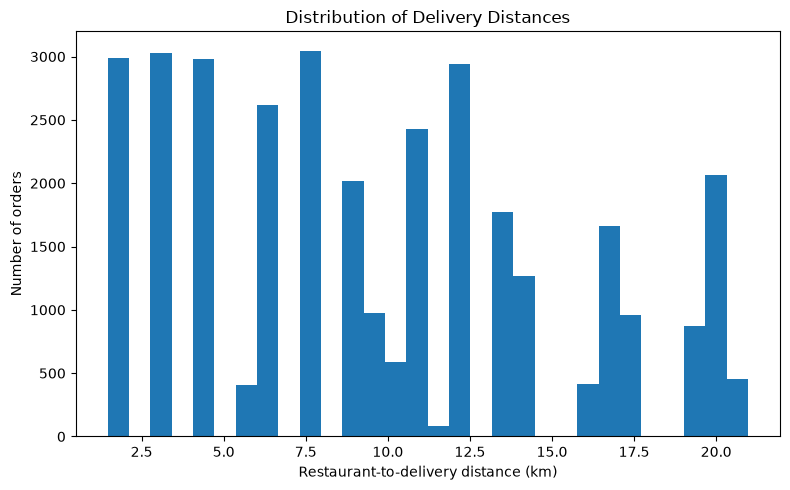

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(X_train["distance_km"], bins=30)
plt.xlabel("Restaurant-to-delivery distance (km)")
plt.ylabel("Number of orders")
plt.title("Distribution of Delivery Distances")
plt.tight_layout()
plt.show()


In [7]:
# Check how many unique restaurant and delivery locations exist
restaurant_locations = X_train[
    ["restaurant_latitude", "restaurant_longitude"]
].drop_duplicates()

delivery_locations = X_train[
    ["delivery_location_latitude", "delivery_location_longitude"]
].drop_duplicates()

print("Unique restaurant locations:", len(restaurant_locations))
print("Unique delivery locations:", len(delivery_locations))

# Inspect the most common distances
print("\nMost common rounded distances:")
print(
    X_train["distance_km"]
    .round(1)
    .value_counts()
    .head(15)
)

Unique restaurant locations: 388
Unique delivery locations: 4333

Most common rounded distances:
distance_km
1.5     2031
3.1     1773
6.1     1255
3.0     1177
6.2     1037
14.0     985
7.8      980
4.6      975
10.9     973
4.7      972
1.6      961
9.3      958
4.5      948
17.1     902
7.6      886
Name: count, dtype: int64


In [9]:
original_features = [
    "weather",
    "traffic_density",
    "vehicle_condition",
    "order_type",
    "vehicle_type",
    "festival",
    "city",
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_location_latitude",
    "delivery_location_longitude",
]
X_train_original = X_train[original_features].copy()
X_test_original = X_test[original_features].copy()

# Experiment 1: Original features
X_train_baseline = X_train_original.copy()
X_test_baseline = X_test_original.copy()

# Experiment 2: Original features + engineered distance
X_train_distance = X_train.copy()
X_test_distance = X_test.copy()

print("Baseline features:", X_train_baseline.shape)
print("Distance features:", X_train_distance.shape)


Baseline features: (33562, 11)
Distance features: (33562, 12)
